<a href="https://colab.research.google.com/github/flomoraes/MATH-440-Log-M--CSF/blob/main/Monte_Carlo2_Save_Curves.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Launching 100000 Monte Carlo simulations in parallel...
Progress: 10000/100000 completed (10%)
Progress: 20000/100000 completed (20%)
Progress: 30000/100000 completed (30%)
Progress: 40000/100000 completed (40%)
Progress: 50000/100000 completed (50%)
Progress: 60000/100000 completed (60%)
Progress: 70000/100000 completed (70%)
Progress: 80000/100000 completed (80%)
Progress: 90000/100000 completed (90%)
Progress: 100000/100000 completed (100%)
Completed 5491 successful runs in 12443.36 seconds!
Saved complete CSV metrics to: csf_results/csf_monte_carlo_results.csv
Found 188 non-trivial curves with T_conv / T_ext > 0.5
Saved vertex coordinate matrices to: csf_results/high_ratio_coordinates.npz


/tmp/ipykernel_5125/605057571.py:310: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(


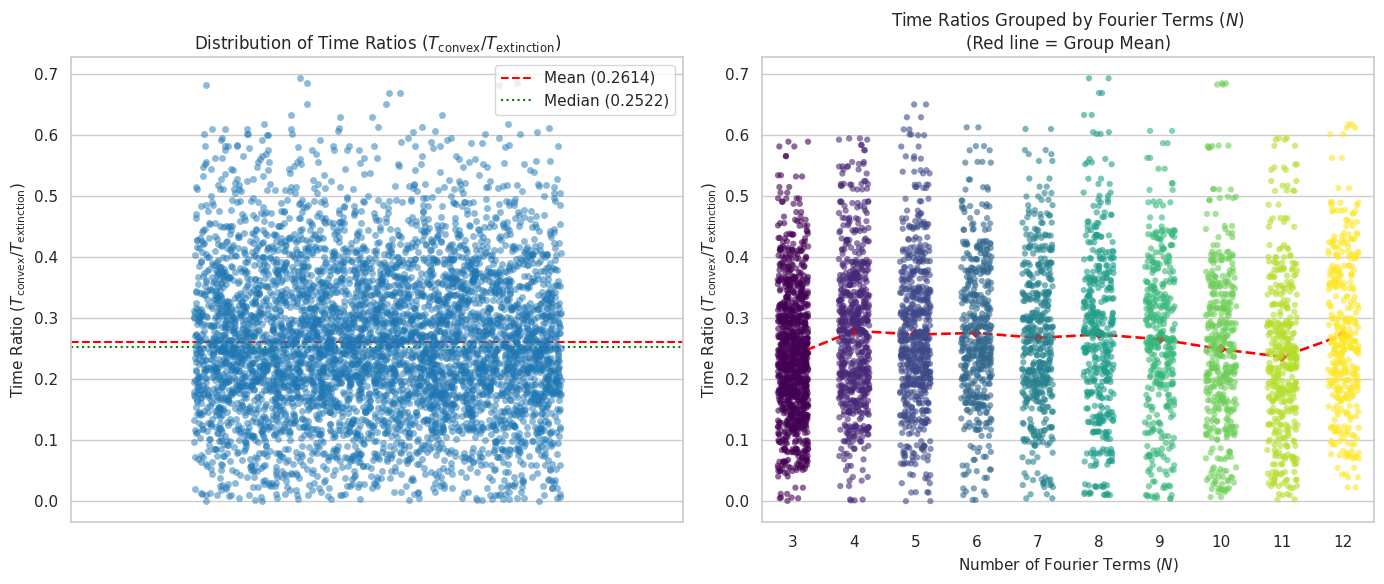

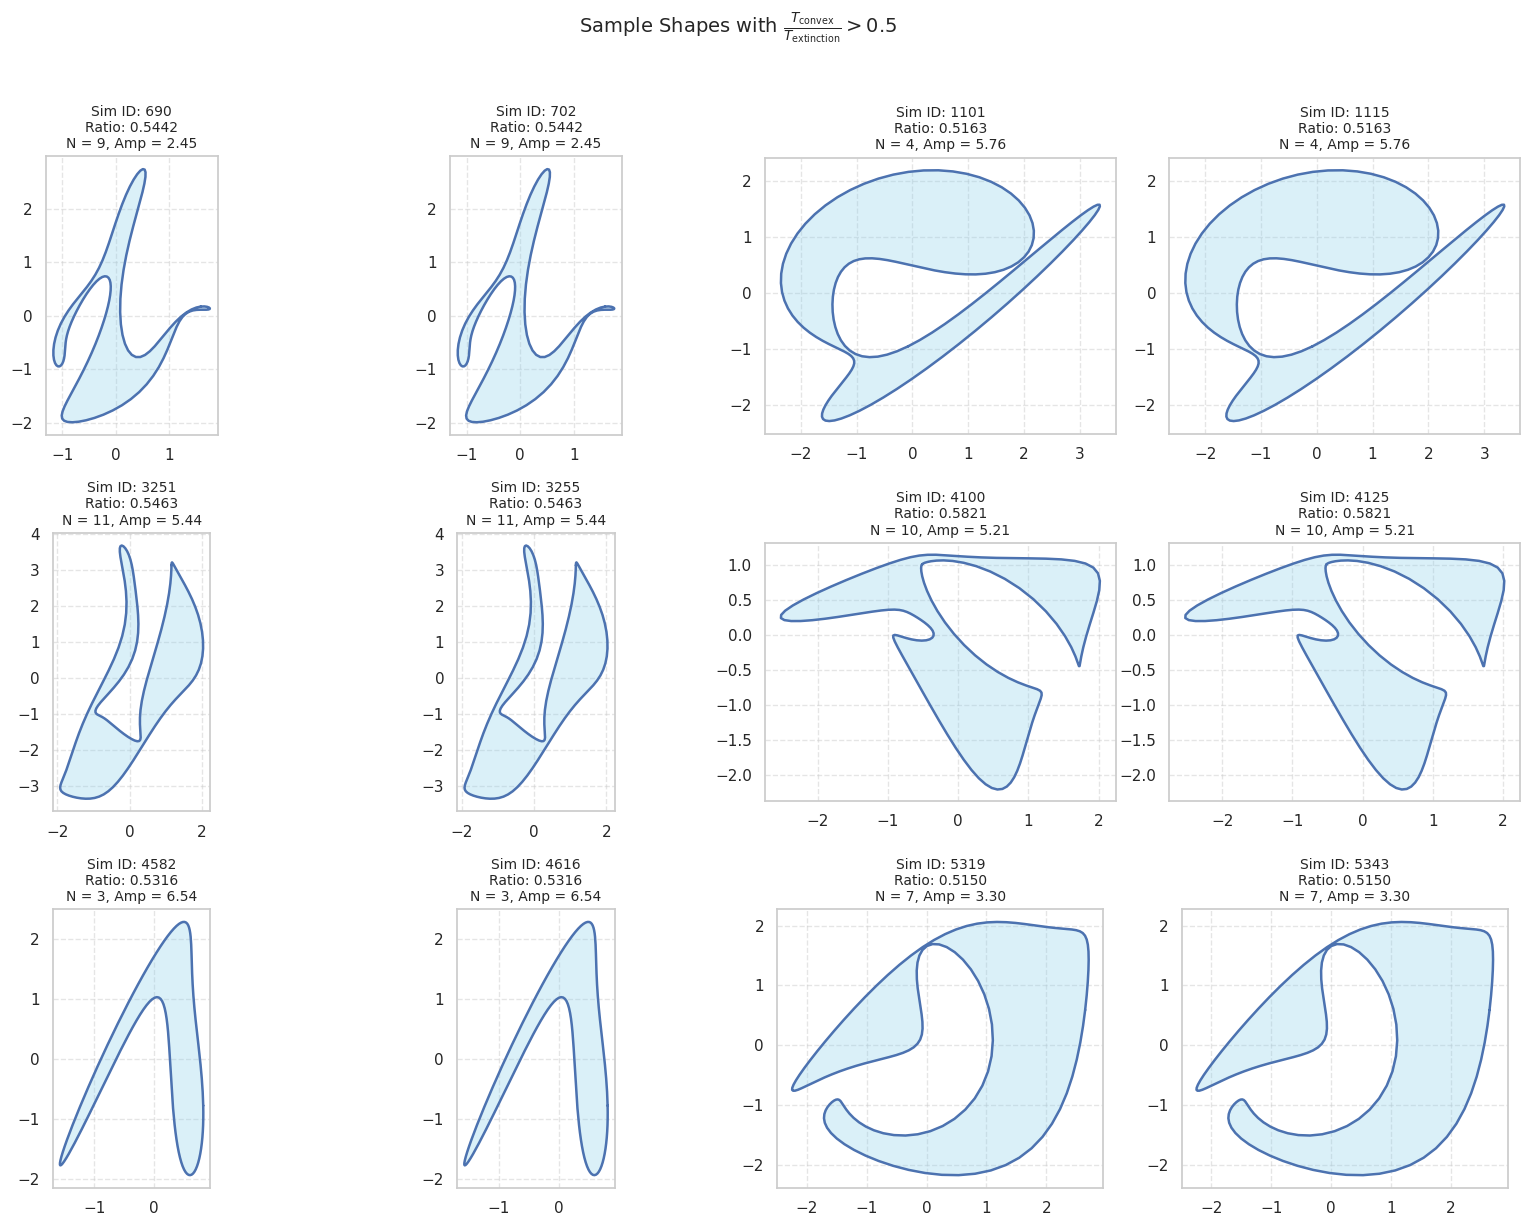

In [ ]:
from concurrent.futures import ProcessPoolExecutor, as_completed
import os
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from shapely.geometry import LineString, Polygon

# =====================================================================
# 1. Fourier Curve Generator & Embeddedness Check
# =====================================================================


def generate_fourier_curve(N_terms, num_points, amp, decay_power):
    """Generates a 2D closed curve using randomized Fourier series[cite: 1].

    x(theta) = cos(theta) + sum_{m=2}^N [ a_m^x cos(m*theta) + b_m^x
    sin(m*theta) ] y(theta) = sin(theta) + sum_{m=2}^N [ a_m^y cos(m*theta) +
    b_m^y sin(m*theta) ]
    """
    theta = np.linspace(0, 2 * np.pi, num_points, endpoint=False)
    x = np.cos(theta)
    y = np.sin(theta)

    for m in range(2, N_terms + 1):
        sigma_m = amp / (m**decay_power)  # High-frequency variance decay[cite: 1]
        ax, bx = np.random.normal(0, sigma_m, 2)
        ay, by = np.random.normal(0, sigma_m, 2)
        x += ax * np.cos(m * theta) + bx * np.sin(m * theta)
        y += ay * np.cos(m * theta) + by * np.sin(m * theta)

    return np.column_stack([x, y])


def is_embedded_shapely(points):
    """Checks if a closed parametric curve is simple (no self-intersections)."""
    closed_pts = np.vstack([points, points[0]])
    return LineString(closed_pts).is_simple and Polygon(points).is_valid


# =====================================================================
# 2. Geometry & Discrete Curve Shortening Flow (CSF) Tools
# =====================================================================


def calculate_signed_curvature(points):
    """Computes pointwise signed curvature kappa using central finite differences."""
    pts = np.vstack([points[-2:], points, points[:2]])
    dx = np.gradient(pts[:, 0])
    dy = np.gradient(pts[:, 1])
    ddx = np.gradient(dx)
    ddy = np.gradient(dy)

    dx, dy = dx[2:-2], dy[2:-2]
    ddx, ddy = ddx[2:-2], ddy[2:-2]

    kappa = (dx * ddy - dy * ddx) / (np.power(dx**2 + dy**2, 1.5) + 1e-12)
    return kappa


def is_convex(points):
    """Returns True if curvature maintains the same sign everywhere."""
    kappa = calculate_signed_curvature(points)
    return np.all(kappa > 0) or np.all(kappa < 0)


def resample_arclength(points):
    """Uniformly resamples vertices along arclength to maintain numerical stability."""
    closed = np.vstack([points, points[0]])
    dists = np.sqrt(np.sum(np.diff(closed, axis=0) ** 2, axis=1))
    cum_dists = np.insert(np.cumsum(dists), 0, 0)
    total_len = cum_dists[-1]

    target_dists = np.linspace(0, total_len, len(points), endpoint=False)
    new_x = np.interp(target_dists, cum_dists, closed[:, 0])
    new_y = np.interp(target_dists, cum_dists, closed[:, 1])
    return np.column_stack([new_x, new_y])


def compute_X_ss(points):
    """Computes discrete second derivative X_ss via midpoint slopes Z_i[cite: 2]:

    Z_i = (X_{i+1} - X_i) / h_i[cite: 2]
    X_ss = (Z_i - Z_{i-1}) / (0.5 * (h_i + h_{i-1}))[cite: 2]
    """
    X_curr = points
    X_next = np.roll(points, -1, axis=0)
    X_prev = np.roll(points, 1, axis=0)

    edge_next = X_next - X_curr
    edge_prev = X_curr - X_prev

    h_next = np.linalg.norm(edge_next, axis=1, keepdims=True)
    h_prev = np.linalg.norm(edge_prev, axis=1, keepdims=True)

    Z_next = edge_next / h_next  # Slope at midpoint Z_i[cite: 2]
    Z_prev = edge_prev / h_prev  # Slope at midpoint Z_{i-1}[cite: 2]

    X_ss = (Z_next - Z_prev) / (0.5 * (h_next + h_prev))  #[cite: 2]
    return X_ss


def simulate_time_to_convexity(points, dt=0.0001, max_steps=10000):
    """Evolves X_{t+dt} = X_t + dt * X_ss until the curve becomes convex[cite: 2]."""
    curr_poly = points.copy()

    if is_convex(curr_poly):
        return 0.0  # Already convex at t = 0

    for step in range(1, max_steps + 1):
        X_ss = compute_X_ss(curr_poly)  #[cite: 2]
        curr_poly += dt * X_ss  # Time stepping update[cite: 2]

        if step % 5 == 0:
            curr_poly = resample_arclength(curr_poly)

        if is_convex(curr_poly):
            return step * dt

    return None  # Flow did not reach convexity within max_steps limit


# =====================================================================
# 3. Worker Function & Parallel Monte Carlo Engine
# =====================================================================


def run_single_simulation(sim_id, param_ranges):
    """Worker task for a single Monte Carlo run."""
    N_terms = np.random.randint(
        param_ranges["N_min"], param_ranges["N_max"] + 1
    )
    amp = np.random.uniform(param_ranges["amp_min"], param_ranges["amp_max"])
    decay_power = np.random.uniform(
        param_ranges["decay_min"], param_ranges["decay_max"]
    )
    num_points = param_ranges["num_points"]

    attempts = 0
    while True:
        attempts += 1
        pts = generate_fourier_curve(N_terms, num_points, amp, decay_power)
        if is_embedded_shapely(pts):
            break
        if attempts > 200:
            return None

    # Geometry & Extinction Time: T_ext = Initial_Area / (2 * pi)
    poly = Polygon(pts)
    initial_area = poly.area
    t_extinction = initial_area / (2 * np.pi)
    initially_convex = is_convex(pts)

    # Time to Convexity via CSF
    t_convexity = simulate_time_to_convexity(pts, dt=0.0001, max_steps=10000)

    if t_convexity is None:
        return None

    return {
        "sim_id": sim_id,
        "N_terms": N_terms,
        "amplitude": amp,
        "decay_power": decay_power,
        "initial_area": initial_area,
        "initially_convex": initially_convex,
        "t_convexity": t_convexity,
        "t_extinction": t_extinction,
        "time_ratio": t_convexity / t_extinction,
        "curve_points": pts,  # Retain initial 2D coordinate array
    }


def run_parallel_monte_carlo(num_simulations=1000, max_workers=None):
    """Executes Monte Carlo simulations in parallel across available CPU cores."""
    param_ranges = {
        "N_min": 3,
        "N_max": 12,
        "amp_min": 0.01,
        "amp_max": 100,
        "decay_min": 1.5,
        "decay_max": 2.5,
        "num_points": 150,
    }

    results = []
    start_time = time.time()
    print(f"Launching {num_simulations} Monte Carlo simulations in parallel...")

    with ProcessPoolExecutor(max_workers=max_workers) as executor:
        futures = [
            executor.submit(run_single_simulation, i, param_ranges)
            for i in range(num_simulations)
        ]

        completed = 0
        for future in as_completed(futures):
            res = future.result()
            if res is not None:
                results.append(res)
            completed += 1
            if completed % max(1, (num_simulations // 10)) == 0:
                print(
                    f"Progress: {completed}/{num_simulations} completed"
                    f" ({(completed/num_simulations)*100:.0f}%)"
                )

    print(
        f"Completed {len(results)} successful runs in"
        f" {time.time() - start_time:.2f} seconds!"
    )
    return results


# =====================================================================
# 4. Data Export, Filtering & Visualizations
# =====================================================================


def process_and_visualize_outcomes(
    results, threshold=0.5, save_dir="csf_results"
):
    os.makedirs(save_dir, exist_ok=True)

    # 1. Convert tabular metrics to pandas DataFrame
    df = pd.DataFrame([
        {k: v for k, v in res.items() if k != "curve_points"} for res in results
    ])
    csv_path = os.path.join(save_dir, "csf_monte_carlo_results.csv")
    df.to_csv(csv_path, index=False)
    print(f"Saved complete CSV metrics to: {csv_path}")

    # 2. Filter high-ratio curves and export coordinate matrices
    high_ratio_runs = [
        res
        for res in results
        if not res["initially_convex"] and res["time_ratio"] > threshold
    ]
    print(
        f"Found {len(high_ratio_runs)} non-trivial curves with T_conv / T_ext >"
        f" {threshold}"
    )

    if high_ratio_runs:
        npz_dict = {
            f"curve_{res['sim_id']}": res["curve_points"]
            for res in high_ratio_runs
        }
        npz_path = os.path.join(save_dir, "high_ratio_coordinates.npz")
        np.savez_compressed(npz_path, **npz_dict)
        print(f"Saved vertex coordinate matrices to: {npz_path}")

    # 3. Figure 1: Dot Plots of Time Ratios
    df_plot = df[~df["initially_convex"]].copy()
    sns.set_theme(style="whitegrid")
    fig1, axes1 = plt.subplots(1, 2, figsize=(14, 6))

    # Plot 1A: Overall Strip Plot
    sns.stripplot(
        data=df_plot,
        y="time_ratio",
        jitter=0.3,
        alpha=0.5,
        size=5,
        color="#1f77b4",
        ax=axes1[0],
    )
    mean_val = df_plot["time_ratio"].mean()
    median_val = df_plot["time_ratio"].median()
    axes1[0].axhline(
        mean_val,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label=f"Mean ({mean_val:.4f})",
    )
    axes1[0].axhline(
        median_val,
        color="green",
        linestyle=":",
        linewidth=1.5,
        label=f"Median ({median_val:.4f})",
    )
    axes1[0].set_title(
        "Distribution of Time Ratios ($T_{\\mathrm{convex}} /"
        " T_{\\mathrm{extinction}}$)",
        fontsize=12,
    )
    axes1[0].set_ylabel(
        "Time Ratio ($T_{\\mathrm{convex}} / T_{\\mathrm{extinction}}$)",
        fontsize=11,
    )
    axes1[0].set_xticks([])
    axes1[0].legend(loc="upper right")

    # Plot 1B: Grouped Dot Plot by Fourier Mode Count N
    sns.stripplot(
        data=df_plot,
        x="N_terms",
        y="time_ratio",
        hue="N_terms",
        palette="viridis",
        jitter=0.25,
        alpha=0.6,
        size=4.5,
        legend=False,
        ax=axes1[1],
    )
    sns.pointplot(
        data=df_plot,
        x="N_terms",
        y="time_ratio",
        estimator=np.mean,
        color="red",
        markers="D",
        scale=0.7,
        linestyles="--",
        errorbar=None,
        ax=axes1[1],
    )
    axes1[1].set_title(
        "Time Ratios Grouped by Fourier Terms ($N$)\n(Red line = Group Mean)",
        fontsize=12,
    )
    axes1[1].set_xlabel("Number of Fourier Terms ($N$)", fontsize=11)
    axes1[1].set_ylabel(
        "Time Ratio ($T_{\\mathrm{convex}} / T_{\\mathrm{extinction}}$)",
        fontsize=11,
    )
    plt.tight_layout()

    # 4. Figure 2: Shape Grid of Curves with Ratio > 0.5
    if high_ratio_runs:
        num_to_plot = min(len(high_ratio_runs), 12)
        cols = 4
        rows = int(np.ceil(num_to_plot / cols))

        fig2, axes2 = plt.subplots(rows, cols, figsize=(16, 4 * rows))
        axes2 = np.array(axes2).flatten()

        for i in range(num_to_plot):
            res = high_ratio_runs[i]
            pts = res["curve_points"]
            closed_pts = np.vstack([pts, pts[0]])

            ax = axes2[i]
            ax.plot(closed_pts[:, 0], closed_pts[:, 1], "b-", linewidth=1.8)
            ax.fill(
                closed_pts[:, 0], closed_pts[:, 1], color="skyblue", alpha=0.3
            )

            title_str = (
                f"Sim ID: {res['sim_id']}\n"
                f"Ratio: {res['time_ratio']:.4f}\n"
                f"N = {res['N_terms']}, Amp = {res['amplitude']:.2f}"
            )
            ax.set_title(title_str, fontsize=10)
            ax.set_aspect("equal")
            ax.grid(True, linestyle="--", alpha=0.5)

        for j in range(num_to_plot, len(axes2)):
            axes2[j].axis("off")

        plt.suptitle(
            r"Sample Shapes with $\frac{T_{\mathrm{convex}}}{T_{\mathrm{extinction}}} > 0.5$",
            fontsize=14,
            y=1.02,
        )
        plt.tight_layout()

    plt.show()


# =====================================================================
# Main Pipeline Execution Entry Point
# =====================================================================
if __name__ == "__main__":
    # 1. Run Monte Carlo simulation pool across CPU cores
    raw_results = run_parallel_monte_carlo(num_simulations=100000)

    # 2. Process data, export files (.csv and .npz), and render dot plots + shape grids
    process_and_visualize_outcomes(raw_results, threshold=0.5)